In [42]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [43]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [44]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.05, 0.05)
], name="data_augmentation")

In [45]:
DATA_DIR = "/content/drive/MyDrive/prepared_data"

import os
print(os.listdir(DATA_DIR))

['test_labels.npy', 'train.npy', 'train_labels.npy', 'test.npy', 'validation_labels.npy', 'validation.npy']


In [46]:
train = np.load(os.path.join(DATA_DIR, "train.npy"), mmap_mode="r")

print("Train shape:", train.shape)
print("Data type:", train.dtype)

Train shape: (16487, 128, 128, 3)
Data type: uint8


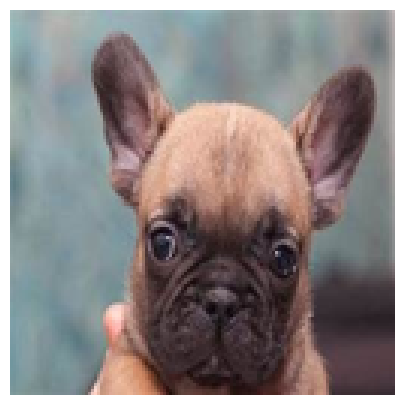

In [47]:
plt.figure(figsize=(5,5))
plt.imshow(train[0])
plt.axis("off")
plt.show()

In [48]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.05, 0.05)
], name="data_augmentation")

In [49]:
sample = train[:4].astype("float32") / 255.0

augmented = data_augmentation(sample, training=True)

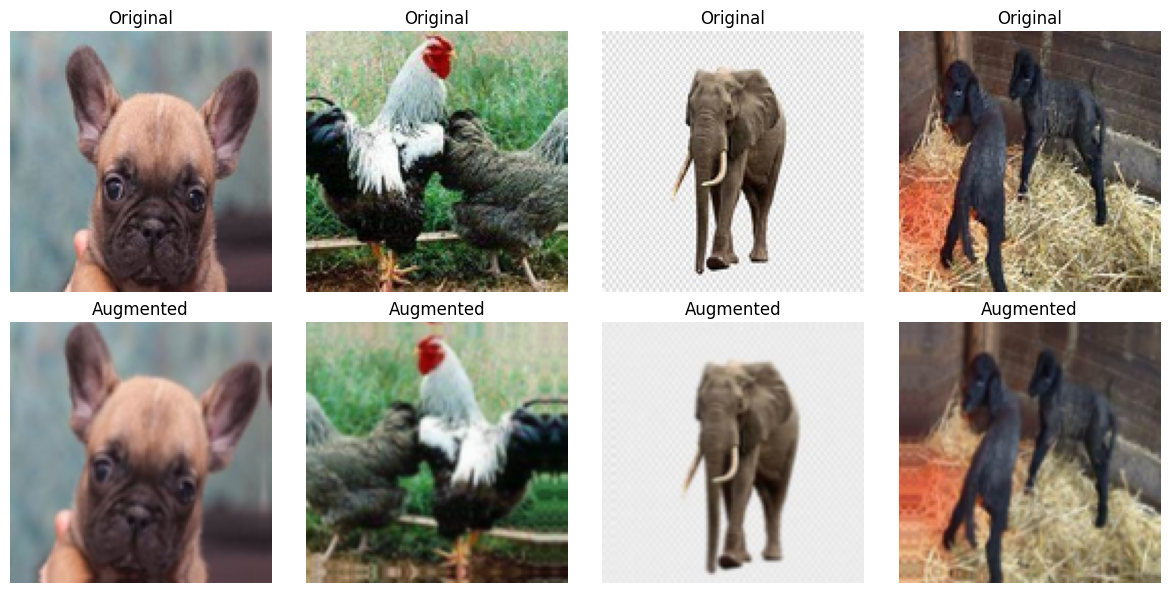

In [50]:
plt.figure(figsize=(12, 6))

for i in range(4):
    plt.subplot(2, 4, i + 1)
    plt.imshow(sample[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(augmented[i])
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()

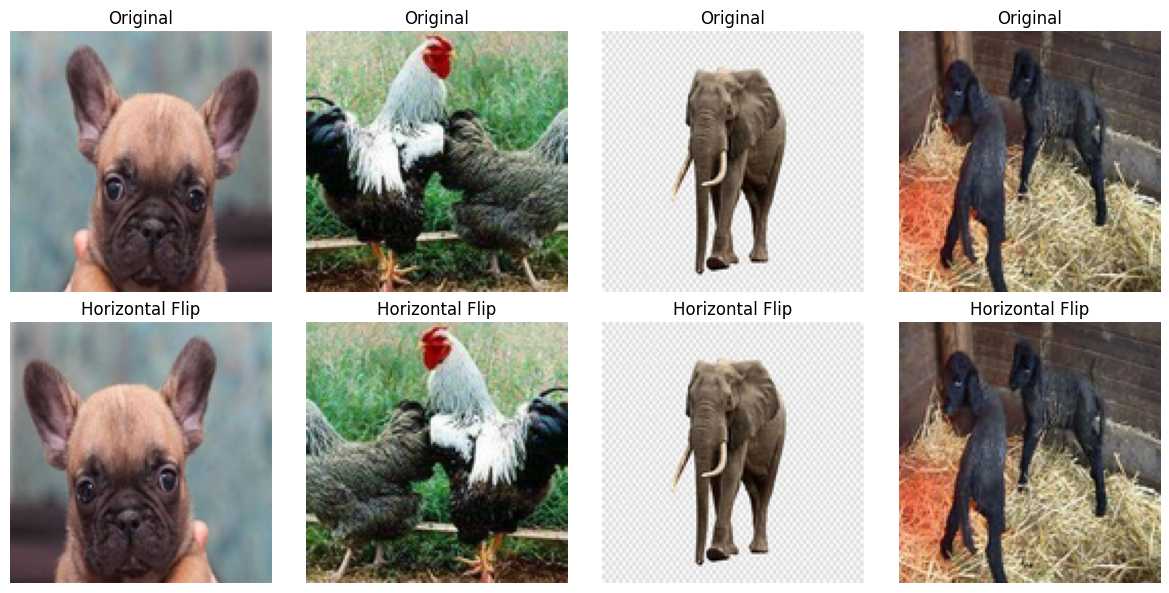

In [51]:
flip_layer = tf.keras.layers.RandomFlip("horizontal")

flipped = flip_layer(sample, training=True)

plt.figure(figsize=(12, 6))

for i in range(4):
    plt.subplot(2, 4, i + 1)
    plt.imshow(sample[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(flipped[i])
    plt.title("Horizontal Flip")
    plt.axis("off")

plt.tight_layout()
plt.show()

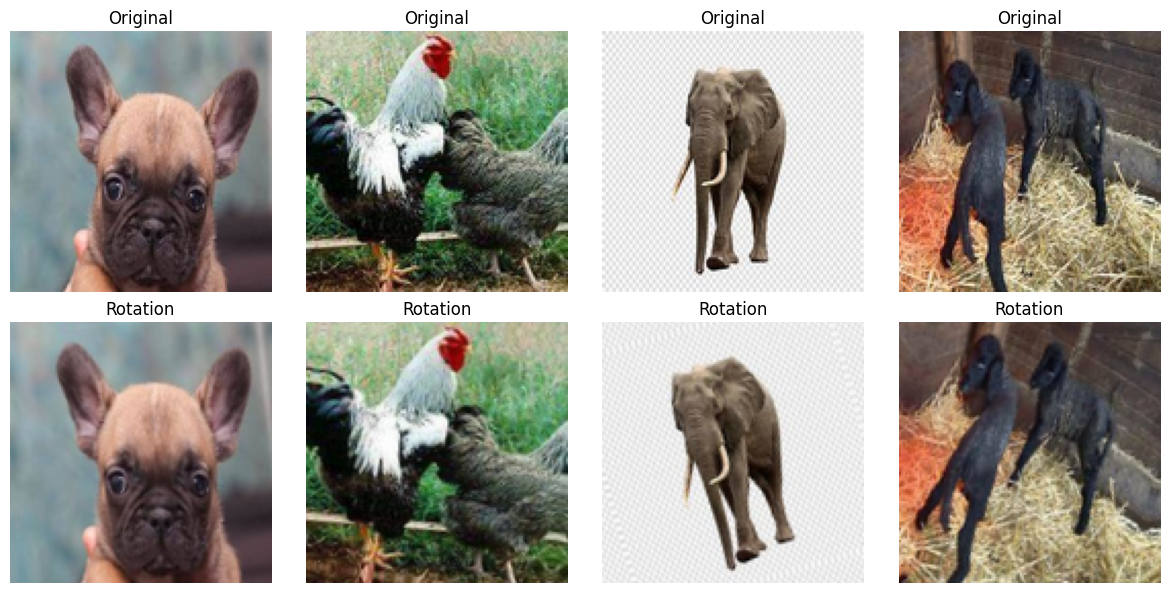

In [52]:
rotation_layer = tf.keras.layers.RandomRotation(0.05)

rotated = rotation_layer(sample, training=True)

plt.figure(figsize=(12, 6))

for i in range(4):
    plt.subplot(2, 4, i + 1)
    plt.imshow(sample[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(rotated[i])
    plt.title("Rotation")
    plt.axis("off")

plt.tight_layout()
plt.show()

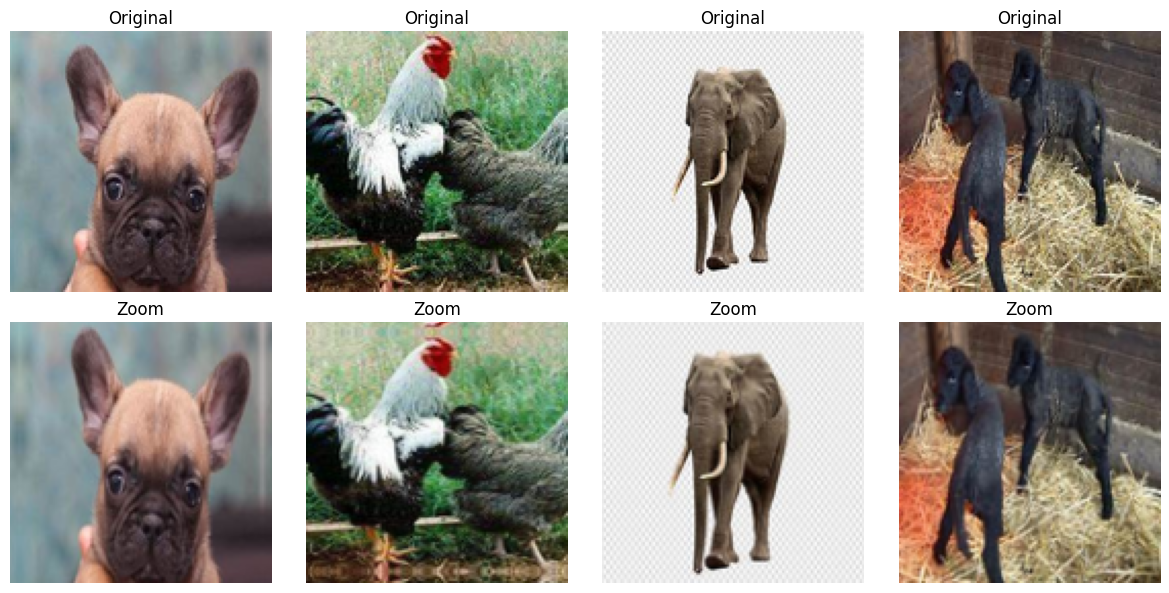

In [53]:
zoom_layer = tf.keras.layers.RandomZoom(
    height_factor=0.10,
    width_factor=0.10
)

zoomed = zoom_layer(sample, training=True)

plt.figure(figsize=(12, 6))

for i in range(4):
    plt.subplot(2, 4, i + 1)
    plt.imshow(sample[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(zoomed[i])
    plt.title("Zoom")
    plt.axis("off")

plt.tight_layout()
plt.show()

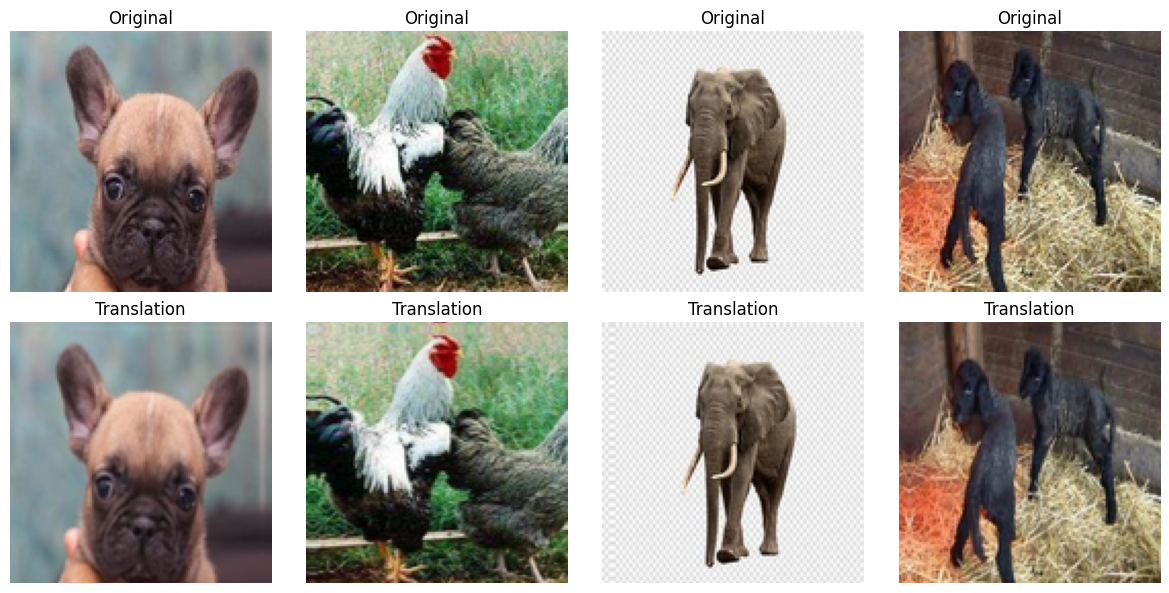

In [54]:
translation_layer = tf.keras.layers.RandomTranslation(
    height_factor=0.05,
    width_factor=0.05
)

translated = translation_layer(sample, training=True)

plt.figure(figsize=(12, 6))

for i in range(4):
    plt.subplot(2, 4, i + 1)
    plt.imshow(sample[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(translated[i])
    plt.title("Translation")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [55]:
test_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomZoom(0.25),
    tf.keras.layers.RandomTranslation(0.15, 0.15)
])

test_result = test_augmentation(sample, training=True)

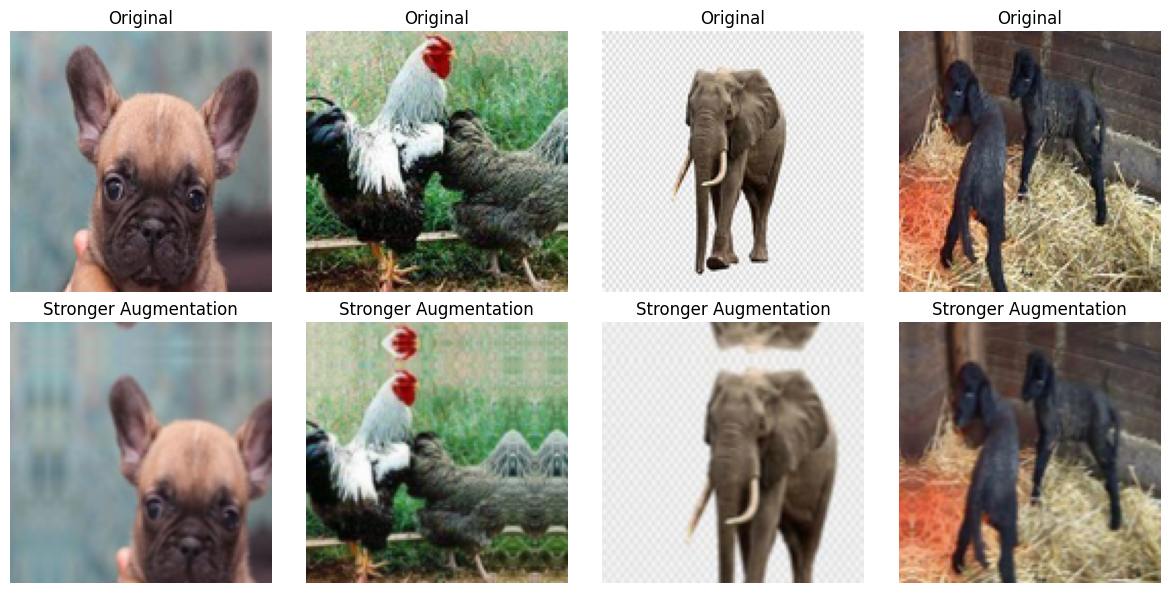

In [56]:
plt.figure(figsize=(12, 6))

for i in range(4):
    plt.subplot(2, 4, i + 1)
    plt.imshow(sample[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(test_result[i])
    plt.title("Stronger Augmentation")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [57]:
RANDOM_STATE = 42

In [58]:
try:
    from tensorflow.keras.utils import Sequence as _BaseSequence
except ImportError:
    _BaseSequence = object


class SplitGenerator(_BaseSequence):

    def __init__(self, images_path, labels_path, batch_size=32, shuffle=False):
        self.images = np.load(images_path, mmap_mode="r")
        self.labels = np.load(labels_path)

        self.batch_size = batch_size
        self.shuffle = shuffle
        self.order = np.arange(len(self.labels))

        self.rng = np.random.default_rng(RANDOM_STATE)

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.labels) / self.batch_size))

    def __getitem__(self, batch_index):
        start = batch_index * self.batch_size
        batch_ids = self.order[start:start + self.batch_size]

        batch_x = np.asarray(
            self.images[batch_ids], dtype=np.float32
        ) / 255.0

        batch_y = self.labels[batch_ids]

        return batch_x, batch_y

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.order)

In [59]:
class AugmentedTrainGenerator(SplitGenerator):

    def __getitem__(self, batch_index):
        batch_x, batch_y = super().__getitem__(batch_index)

        batch_x = self.augmentation(
            batch_x,
            training=True
        ).numpy()

        return batch_x, batch_y

    def __init__(self, *args, augmentation, **kwargs):
        super().__init__(*args, **kwargs)
        self.augmentation = augmentation

In [60]:
BATCH_SIZE = 32

train_aug_gen = AugmentedTrainGenerator(
    os.path.join(DATA_DIR, "train.npy"),
    os.path.join(DATA_DIR, "train_labels.npy"),
    batch_size=BATCH_SIZE,
    shuffle=True,
    augmentation=data_augmentation
)

In [61]:
images, labels = train_aug_gen[0]

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image range:", images.min(), images.max())
print("Labels:", labels[:10])

Images shape: (32, 128, 128, 3)
Labels shape: (32,)
Image range: 0.0 1.0
Labels: [8 7 3 7 8 4 8 4 8 5]


In [62]:
val_gen = SplitGenerator(
    os.path.join(DATA_DIR, "validation.npy"),
    os.path.join(DATA_DIR, "validation_labels.npy"),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_gen = SplitGenerator(
    os.path.join(DATA_DIR, "test.npy"),
    os.path.join(DATA_DIR, "test_labels.npy"),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Validation samples:", len(val_gen.labels))
print("Testing samples:", len(test_gen.labels))
print("Validation/Test augmentation: Disabled")

Validation samples: 3533
Testing samples: 3534
Validation/Test augmentation: Disabled


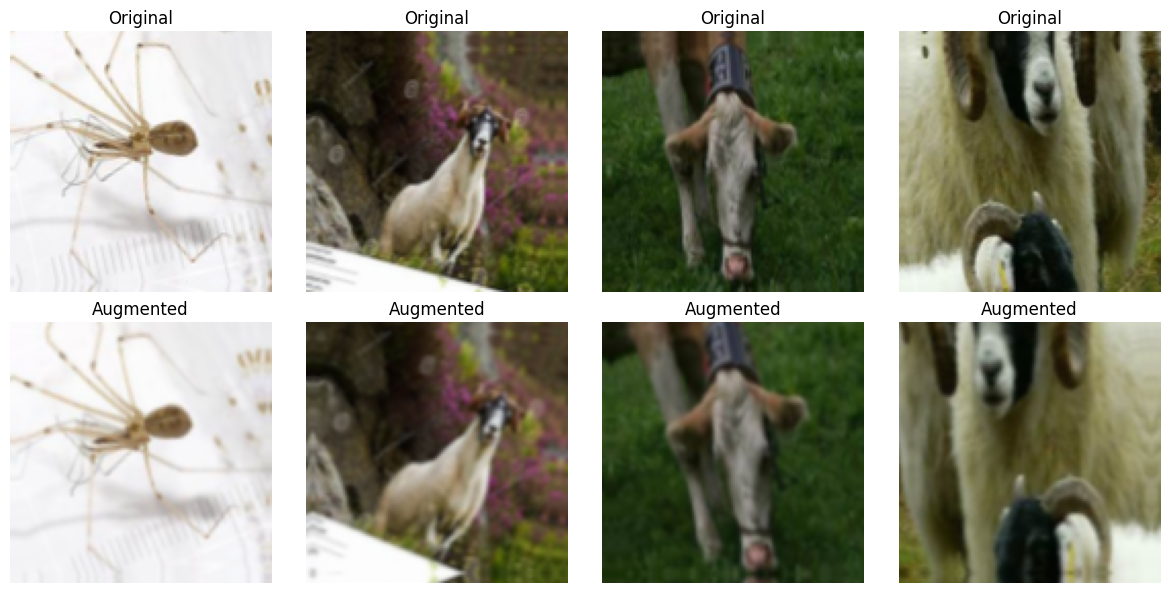

In [63]:
import matplotlib.pyplot as plt

original_images = images[:4]
augmented_images = data_augmentation(
    original_images,
    training=True
).numpy()

plt.figure(figsize=(12, 6))

for i in range(4):
    plt.subplot(2, 4, i + 1)
    plt.imshow(original_images[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(augmented_images[i])
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.savefig("augmentation_examples.png", dpi=300, bbox_inches="tight")
plt.show()